# UTS Pemodelan dan Simulasi: Sistem Dinamik Ketersediaan Beras Provinsi Jawa Barat

Notebook ini memuat pembuatan model komputer dan uji teori untuk artikel UTS.
Model yang sama dipakai oleh aplikasi web Flask (`model.py`).

**Alur:** (1) siapkan data, (2) estimasi parameter, (3) simulasi dan validasi,
(4) uji teori Euler vs Runge-Kutta 4, (5) skenario proyeksi.

**Sumber data**
- Produksi beras bulanan Jawa Barat 2020-2025: Open Data Jabar / BPS (ton).
- Konsumsi beras per kapita kab/kota 2021-2025: dataset konsumsi pangan (satuan diasumsikan kg/kapita/tahun, **konfirmasi dari metadata sumber**).
- Populasi: proyeksi penduduk BPS Jabar 2020-2035 (titik 2020 dan 2025), tahun di antaranya diinterpolasi geometrik.

## 1. Kode model
Sel berikut menulis `model.py` (stock and flow bulanan, solver Euler dan RK4).

In [ ]:
%%writefile model.py
"""Model System Dynamics bulanan: Ketersediaan Beras Provinsi Jawa Barat.

Stock : Populasi P, Konsumsi per kapita k, Level produksi Q (ton/thn),
        Stok surplus S, Produksi kumulatif Cp, Konsumsi kumulatif Cc
Flow  : laju tumbuh P, k, Q (kontinu); produksi musiman; konsumsi; impor
Solver: Euler dan Runge-Kutta 4 (dibandingkan untuk uji teori)

dP/dt = r_p P          dk/dt = r_k k          dQ/dt = r_q Q
dS/dt = 12*share_m*Q + impor - P*k/1000      (ton/tahun, t dalam tahun)

Hanya pustaka standar Python (ringan untuk Vercel).
"""
import csv
import math
import os

NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
              "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]


# ---------------------------------------------------------------- data
def load_data(folder):
    """Baca produksi_bulanan.csv dan data_tahunan.csv."""
    bulanan = []
    with open(os.path.join(folder, "produksi_bulanan.csv"), newline="", encoding="utf-8") as f:
        for r in csv.DictReader(f):
            bulanan.append((int(r["tahun"]), int(r["bulan"]), float(r["produksi_beras_ton"])))
    tahunan = {}
    with open(os.path.join(folder, "data_tahunan.csv"), newline="", encoding="utf-8") as f:
        for r in csv.DictReader(f):
            tahunan[int(r["tahun"])] = {
                "populasi": float(r["populasi"]),
                "konsumsi_kg": float(r["konsumsi_beras_kg_kapita"]) if r["konsumsi_beras_kg_kapita"] else None,
            }
    return {"bulanan": bulanan, "tahunan": tahunan}


def produksi_tahunan(bulanan):
    out = {}
    for t, _, v in bulanan:
        out[t] = out.get(t, 0.0) + v
    return out


# ------------------------------------------------------------ estimasi
def fit_exp(ts, nilai):
    """Regresi log-linear ln(x)=a+b*t. Kembalikan (a, b); b = laju kontinu/tahun."""
    n = len(ts)
    ys = [math.log(v) for v in nilai]
    mt, my = sum(ts) / n, sum(ys) / n
    b = sum((t - mt) * (y - my) for t, y in zip(ts, ys)) / sum((t - mt) ** 2 for t in ts)
    return my - b * mt, b


def estimasi(data, tahun_terakhir):
    """Estimasi parameter memakai data sampai tahun_terakhir (inklusif)."""
    prod = produksi_tahunan([x for x in data["bulanan"] if x[0] <= tahun_terakhir])
    ys = sorted(prod)
    aq, bq = fit_exp([y + 0.5 for y in ys], [prod[y] for y in ys])      # produksi (ton/thn)
    pp = [(y, d["populasi"]) for y, d in sorted(data["tahunan"].items()) if y <= tahun_terakhir]
    ap, bp = fit_exp([y + 0.5 for y, _ in pp], [v for _, v in pp])
    kk = [(y, d["konsumsi_kg"]) for y, d in sorted(data["tahunan"].items())
          if y <= tahun_terakhir and d["konsumsi_kg"]]
    ak, bk = fit_exp([y + 0.5 for y, _ in kk], [v for _, v in kk])
    # pola musiman: rata-rata porsi bulanan per tahun
    share = [0.0] * 12
    for y in ys:
        tot = prod[y]
        for t, m, v in data["bulanan"]:
            if t == y:
                share[m - 1] += v / tot / len(ys)
    return {
        "a_q": aq, "r_q": bq, "a_p": ap, "r_p": bp, "a_k": ak, "r_k": bk,
        "share": share,
        "tahun_latih": (ys[0], ys[-1]),
        "n_tahun_latih": len(ys),
        "n_tahun_konsumsi": len(kk),
    }


def parameter_awal(est, tahun_mulai):
    """Kondisi awal pada 1 Januari tahun_mulai dari garis regresi."""
    t0 = float(tahun_mulai)
    return {
        "P0": math.exp(est["a_p"] + est["r_p"] * t0),
        "k0": math.exp(est["a_k"] + est["r_k"] * t0),
        "Q0": math.exp(est["a_q"] + est["r_q"] * t0),
    }


# --------------------------------------------------------------- model
def turunan(s, p, m):
    """Turunan state s=[P,k,Q,S,Cp,Cc] pada bulan ke-m (0..11)."""
    P, k, Q, S, Cp, Cc = s
    produksi = 12.0 * p["share"][m] * Q          # ton/thn (laju sesaat)
    konsumsi = P * k / 1000.0                     # ton/thn
    return [p["r_p"] * P, p["r_k"] * k, p["r_q"] * Q,
            produksi + p["impor"] - konsumsi, produksi, konsumsi]


def _euler(s, p, h, m):
    d = turunan(s, p, m)
    return [x + h * dx for x, dx in zip(s, d)]


def _rk4(s, p, h, m):
    k1 = turunan(s, p, m)
    k2 = turunan([x + h / 2 * a for x, a in zip(s, k1)], p, m)
    k3 = turunan([x + h / 2 * a for x, a in zip(s, k2)], p, m)
    k4 = turunan([x + h * a for x, a in zip(s, k3)], p, m)
    return [x + h / 6 * (a + 2 * b + 2 * c + d)
            for x, a, b, c, d in zip(s, k1, k2, k3, k4)]


def simulasi(p, tahun_mulai, n_bulan, metode="euler", sub=1):
    """Simulasi bulanan mulai 1 Jan tahun_mulai. Kembalikan daftar hasil per bulan."""
    step = _rk4 if metode == "rk4" else _euler
    sub = max(1, int(sub))
    h = (1.0 / 12.0) / sub
    s = [p["P0"], p["k0"], p["Q0"], p["S0"], 0.0, 0.0]
    hasil = []
    for i in range(n_bulan):
        m = i % 12
        awal = (s[4], s[5])
        for _ in range(sub):
            s = step(s, p, h, m)
        hasil.append({
            "tahun": tahun_mulai + i // 12, "bulan": m + 1,
            "populasi": s[0], "konsumsi_kg_kapita": s[1],
            "produksi_ton": s[4] - awal[0], "konsumsi_ton": s[5] - awal[1],
            "stok_ton": s[3],
        })
    return hasil


def ringkas_tahunan(hasil_bulanan):
    out = {}
    for r in hasil_bulanan:
        a = out.setdefault(r["tahun"], {"tahun": r["tahun"], "produksi_ton": 0.0,
                                        "konsumsi_ton": 0.0})
        a["produksi_ton"] += r["produksi_ton"]
        a["konsumsi_ton"] += r["konsumsi_ton"]
        a["stok_akhir_ton"] = r["stok_ton"]
        a["populasi"] = r["populasi"]
        a["konsumsi_kg_kapita"] = r["konsumsi_kg_kapita"]
    for a in out.values():
        a["rasio_ketersediaan"] = (a["produksi_ton"] / a["konsumsi_ton"]
                                   if a["konsumsi_ton"] else None)
    return [out[t] for t in sorted(out)]


# ------------------------------------------------------------ validasi
def mape(aktual, prediksi):
    return 100.0 * sum(abs(a - f) / abs(a) for a, f in zip(aktual, prediksi)) / len(aktual)


def rmse(aktual, prediksi):
    return math.sqrt(sum((a - f) ** 2 for a, f in zip(aktual, prediksi)) / len(aktual))


def validasi(data, impor=0.0, metode="euler", sub=1, tahun_uji=None):
    """Latih sampai tahun_uji-1, simulasi dari 2020, bandingkan dengan tahun_uji."""
    tahun_uji = tahun_uji or max(t for t, _, _ in data["bulanan"])
    est = estimasi(data, tahun_uji - 1)
    t_awal = min(t for t, _, _ in data["bulanan"])
    p = dict(est)
    p.update(parameter_awal(est, t_awal))
    p.update(impor=impor, S0=0.0)
    n = (tahun_uji - t_awal + 1) * 12
    sim = simulasi(p, t_awal, n, metode, sub)

    uji_sim = [r for r in sim if r["tahun"] == tahun_uji]
    uji_obs = [v for t, _, v in data["bulanan"] if t == tahun_uji]
    prod_s = [r["produksi_ton"] for r in uji_sim]
    out = {
        "tahun_uji": tahun_uji,
        "tahun_latih": est["tahun_latih"],
        "produksi_bulanan": {"mape_persen": mape(uji_obs, prod_s), "rmse_ton": rmse(uji_obs, prod_s)},
        "bulanan_uji": {"bulan": NAMA_BULAN, "aktual": uji_obs, "simulasi": prod_s},
    }
    pa, ps = sum(uji_obs), sum(prod_s)
    out["produksi_tahunan"] = {"aktual_ton": pa, "simulasi_ton": ps,
                               "galat_persen": 100.0 * (ps - pa) / pa}
    d = data["tahunan"].get(tahun_uji, {})
    if d.get("populasi"):
        pop_s = uji_sim[5]["populasi"]
        out["populasi"] = {"aktual": d["populasi"], "simulasi": pop_s,
                           "galat_persen": 100.0 * (pop_s - d["populasi"]) / d["populasi"]}
    if d.get("konsumsi_kg"):
        ks = sum(r["konsumsi_kg_kapita"] for r in uji_sim) / 12
        out["konsumsi_kapita"] = {"aktual": d["konsumsi_kg"], "simulasi": ks,
                                  "galat_persen": 100.0 * (ks - d["konsumsi_kg"]) / d["konsumsi_kg"]}
    return out


Writing model.py


## 2. Unggah data
Unggah dua berkas: `produksi_bulanan.csv` dan `data_tahunan.csv`.

In [ ]:
import os
os.makedirs("data", exist_ok=True)
try:
    from google.colab import files
    up = files.upload()                      # pilih kedua CSV
    for nama, isi in up.items():
        open(os.path.join("data", nama), "wb").write(isi)
except ImportError:
    print("Bukan di Colab: pastikan folder data/ sudah berisi kedua CSV.")
print(os.listdir("data"))

Bukan di Colab: pastikan folder data/ sudah berisi kedua CSV.
['produksi_bulanan.csv', 'data_tahunan.csv']


## 3. Muat data

In [ ]:
import pandas as pd
import model

data = model.load_data("data")
df_bulan = pd.DataFrame(data["bulanan"], columns=["tahun", "bulan", "produksi_ton"])
df_tahun = pd.DataFrame(data["tahunan"]).T.rename_axis("tahun").reset_index()
prod_th = model.produksi_tahunan(data["bulanan"])
df_tahun["produksi_tahunan_ton"] = df_tahun["tahun"].map(prod_th)
display(df_tahun)
print("Jumlah titik data bulanan:", len(df_bulan))

,tahun,populasi,konsumsi_kg,produksi_tahunan_ton
0,2020,48152280.0,NaN,5207024.94
1,2021,48662688.0,96.947,5262925.39
2,2022,49178507.0,95.058,5447806.31
3,2023,49699793.0,94.482,5278209.20
4,2024,50226604.0,92.864,4981868.86
5,2025,50759000.0,86.771,5905709.64


Jumlah titik data bulanan: 72


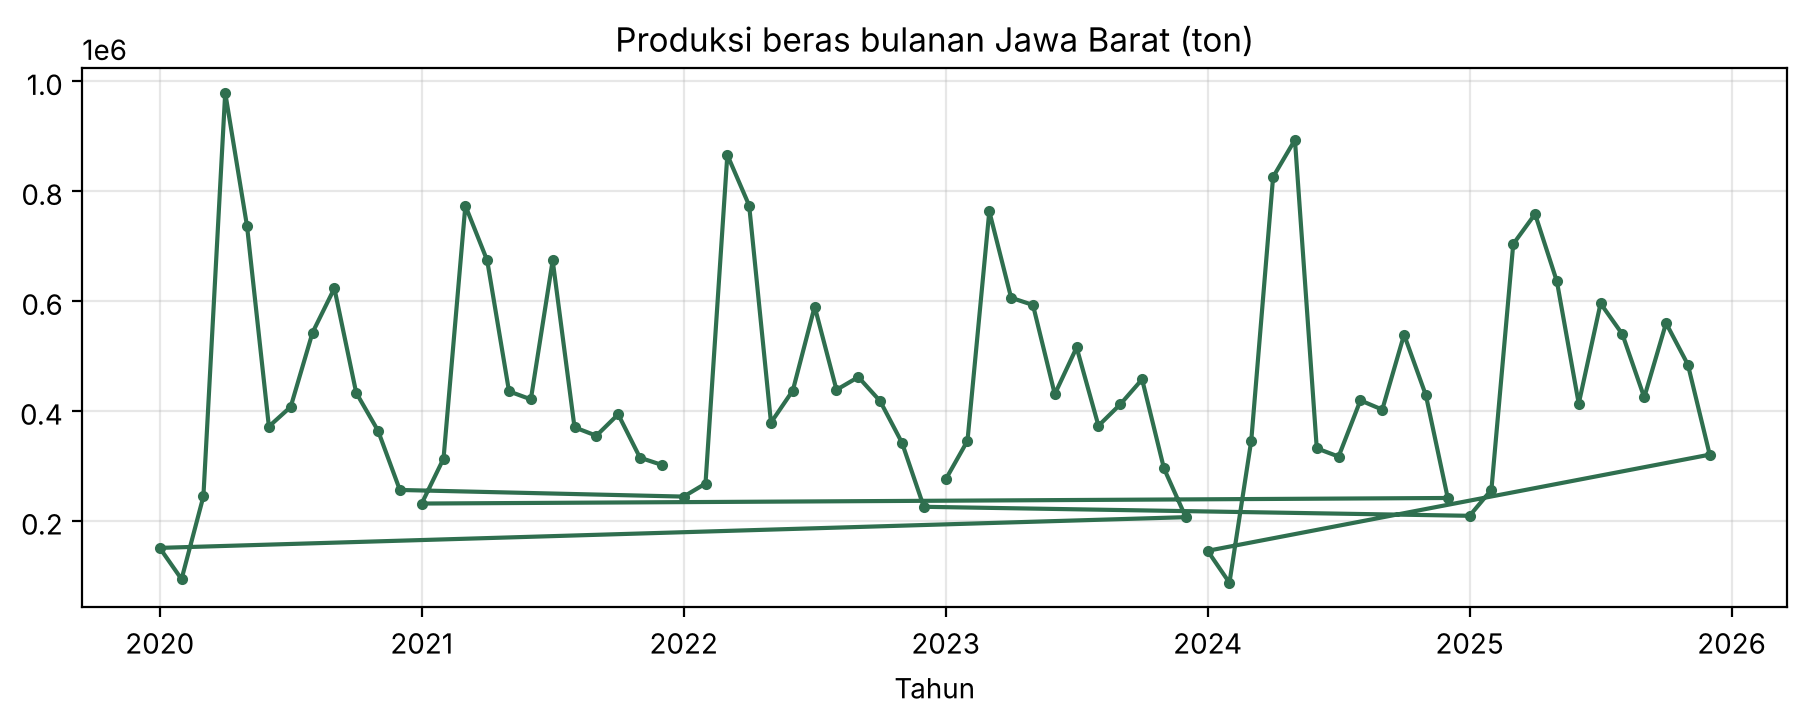

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11, 3.5))
x = [t + (m - 1) / 12 for t, m, _ in data["bulanan"]]
ax.plot(x, [v for _, _, v in data["bulanan"]], marker="o", ms=3, color="#2f6f4f")
ax.set_title("Produksi beras bulanan Jawa Barat (ton)")
ax.set_xlabel("Tahun"); ax.grid(alpha=.3); plt.show()

## 4. Estimasi parameter
Laju pertumbuhan kontinu diperoleh dari regresi log-linear: ln(x) = a + b t.
Pola musiman produksi dihitung dari rata-rata porsi tiap bulan terhadap total tahunan.

In [ ]:
est = model.estimasi(data, 2025)
print(f"r_populasi  = {est['r_p']*100:.3f} %/thn")
print(f"r_produksi  = {est['r_q']*100:.3f} %/thn")
print(f"r_konsumsi  = {est['r_k']*100:.3f} %/thn (per kapita)")
pd.Series(est["share"], index=model.NAMA_BULAN, name="porsi musiman").round(4).to_frame().T

r_populasi  = 1.054 %/thn
r_produksi  = 1.238 %/thn
r_konsumsi  = -2.451 %/thn (per kapita)


,Jan,Feb,Mar,Apr,Mei,Jun,Jul,Agu,Sep,Okt,Nov,Des
porsi musiman,0.0392,0.0423,0.1144,0.1446,0.1156,0.075,0.0962,0.0836,0.0838,0.0875,0.0695,0.0484


## 5. Simulasi dan validasi
Parameter dilatih dengan data **2020-2024**, model disimulasikan dari Januari 2020,
lalu hasil tahun **2025** dibandingkan dengan data aktual (MAPE dan RMSE).

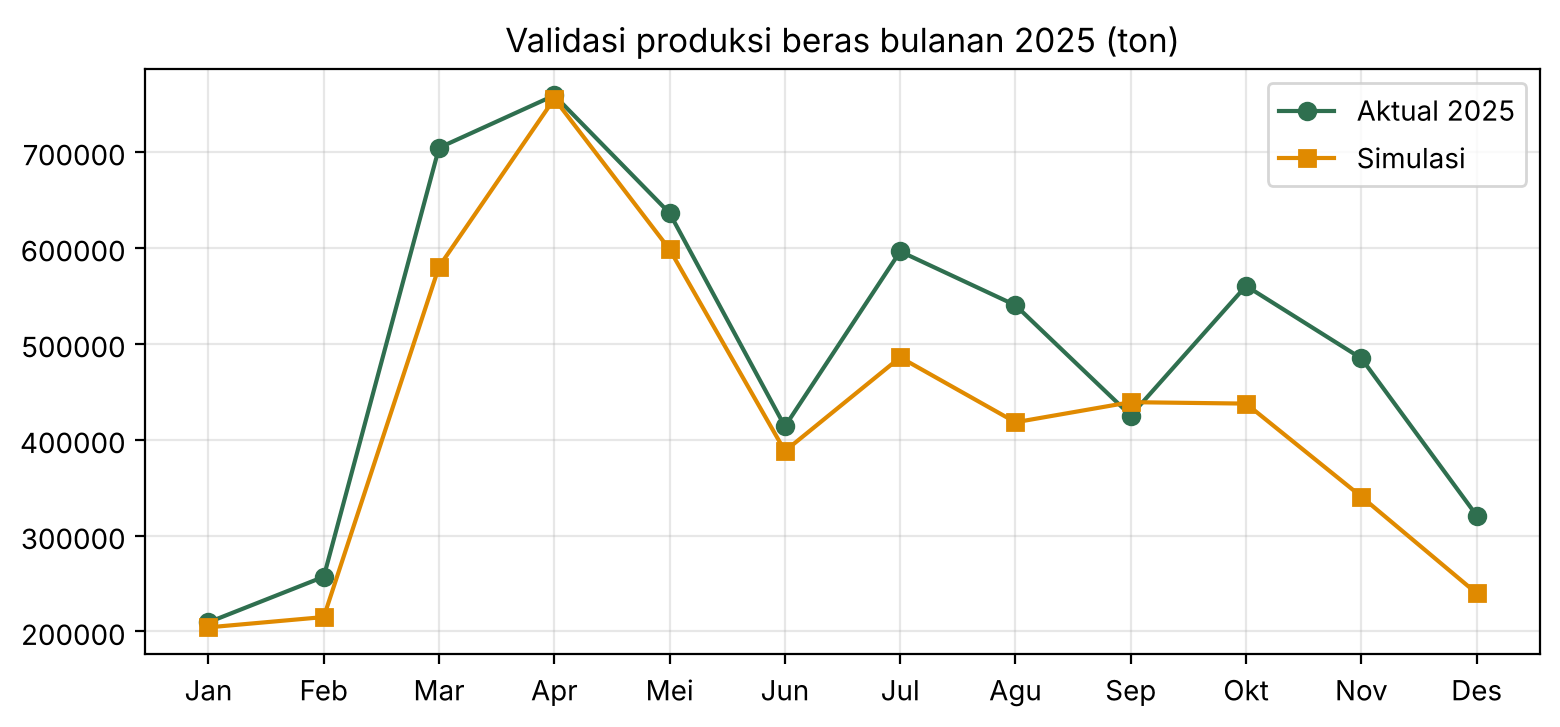

,Ukuran,Nilai
0,Produksi bulanan (MAPE %),14.195
1,Produksi bulanan (RMSE ton),86059.064
2,Produksi tahunan galat %,-13.620
3,Konsumsi kg/kapita galat %,5.594


In [ ]:
v = model.validasi(data, impor=0.0, metode="rk4", sub=1)
bu = v["bulanan_uji"]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(bu["bulan"], bu["aktual"], marker="o", label="Aktual 2025", color="#2f6f4f")
ax.plot(bu["bulan"], bu["simulasi"], marker="s", label="Simulasi", color="#e08a00")
ax.set_title("Validasi produksi beras bulanan 2025 (ton)"); ax.legend(); ax.grid(alpha=.3)
plt.show()

hasil = pd.DataFrame([
    ["Produksi bulanan (MAPE %)", v["produksi_bulanan"]["mape_persen"]],
    ["Produksi bulanan (RMSE ton)", v["produksi_bulanan"]["rmse_ton"]],
    ["Produksi tahunan galat %", v["produksi_tahunan"]["galat_persen"]],
    ["Konsumsi kg/kapita galat %", v["konsumsi_kapita"]["galat_persen"]],
], columns=["Ukuran", "Nilai"]).round(3)
display(hasil)

## 6. Uji teori: Euler vs Runge-Kutta 4
Sub-langkah per bulan diperbanyak. Galat dihitung terhadap solusi acuan
(RK4 dengan 64 sub-langkah). Galat Euler seharusnya turun sekitar separuh setiap
sub-langkah digandakan (orde 1), sedangkan RK4 sudah sangat kecil (orde 4).

,sub-langkah/bulan,galat Euler (ton),galat RK4 (ton)
0,1,50611.3349,0.0
1,2,25299.7159,0.0
2,4,12648.3734,0.0
3,8,6323.8160,0.0
4,16,3161.8154,0.0


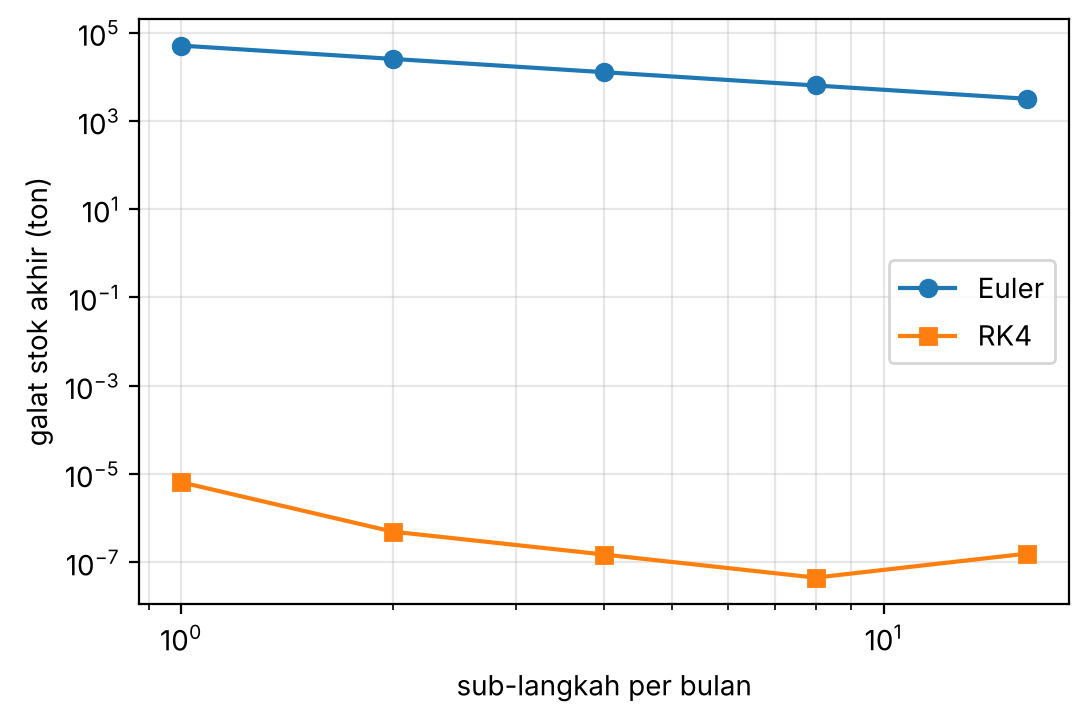

In [ ]:
est_all = model.estimasi(data, 2025)
p = dict(est_all); p.update(model.parameter_awal(est_all, 2026)); p.update(impor=0.0, S0=0.0)
N = 120  # 10 tahun
acuan = model.simulasi(p, 2026, N, "rk4", sub=64)[-1]["stok_ton"]

baris = []
for sub in (1, 2, 4, 8, 16):
    e = model.simulasi(p, 2026, N, "euler", sub)[-1]["stok_ton"]
    r = model.simulasi(p, 2026, N, "rk4", sub)[-1]["stok_ton"]
    baris.append([sub, abs(e - acuan), abs(r - acuan)])
uji = pd.DataFrame(baris, columns=["sub-langkah/bulan", "galat Euler (ton)", "galat RK4 (ton)"])
display(uji.round(4))

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.loglog(uji.iloc[:, 0], uji.iloc[:, 1], "o-", label="Euler")
ax.loglog(uji.iloc[:, 0], uji.iloc[:, 2].clip(lower=1e-9), "s-", label="RK4")
ax.set_xlabel("sub-langkah per bulan"); ax.set_ylabel("galat stok akhir (ton)")
ax.legend(); ax.grid(alpha=.3, which="both"); plt.show()

## 7. Skenario proyeksi 2026-2035
Tiga skenario (selisih terhadap laju tren, poin persen per tahun):
- **Tren**: semua laju sesuai estimasi.
- **Konsumsi datar**: laju konsumsi per kapita disetel 0 (tren turunnya tidak dilanjutkan).
- **Produktivitas naik**: konsumsi datar, produksi tumbuh 1 poin lebih cepat.

Catatan: "stok" adalah akumulasi surplus produksi dikurangi konsumsi rumah tangga,
bukan stok gudang, karena aliran keluar provinsi dan konsumsi non-rumah tangga tidak dimodelkan.

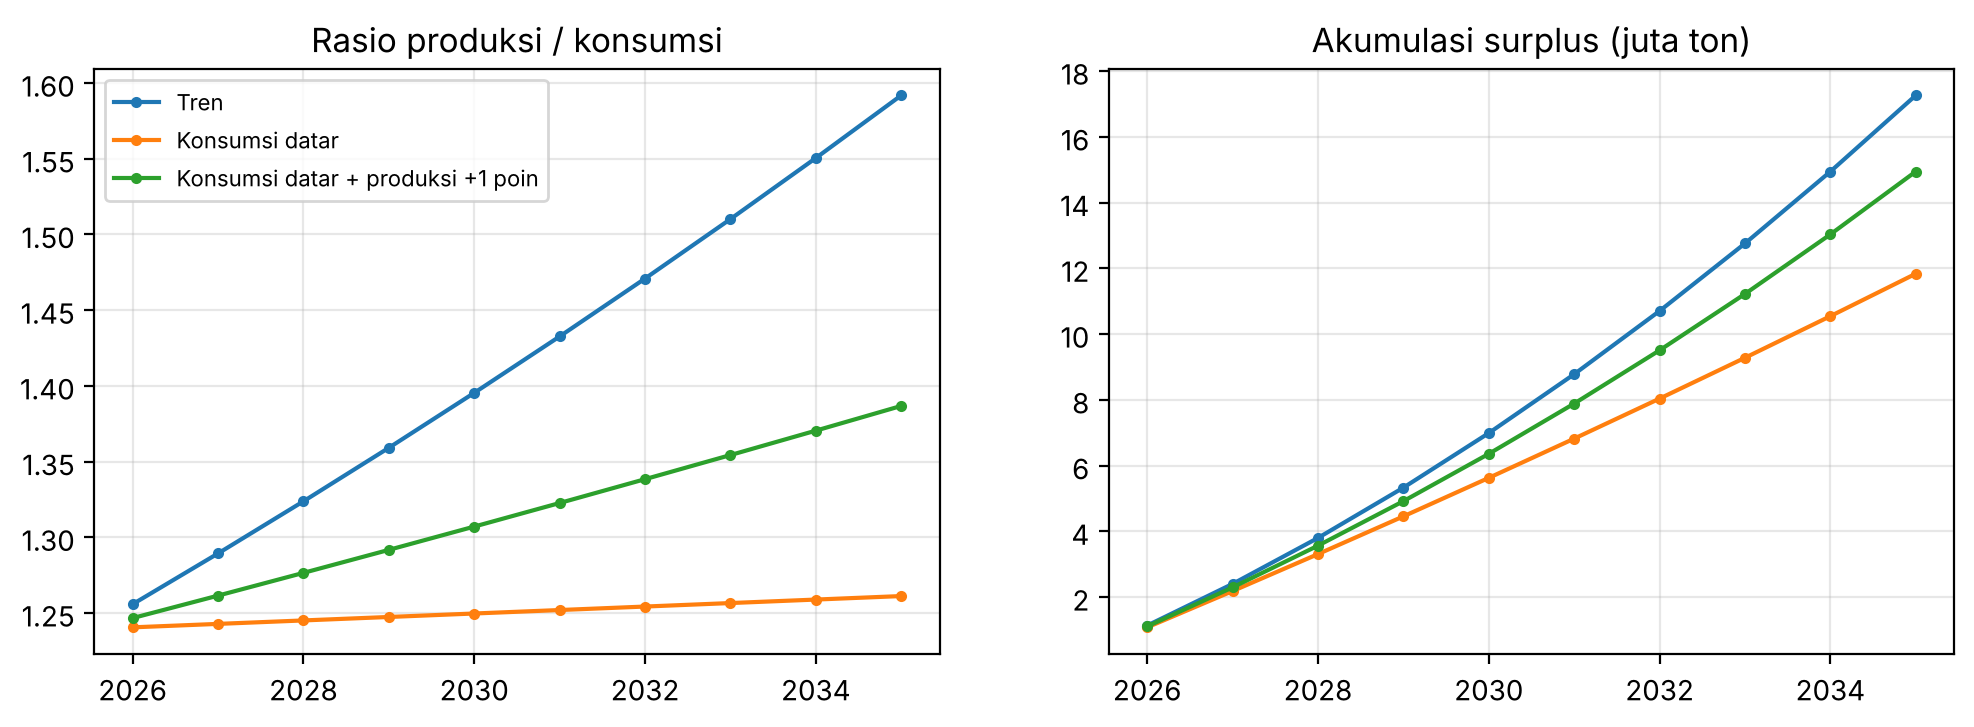

,rasio 2035,surplus 2035 (juta ton)
Tren,1.592,17.261
Konsumsi datar,1.261,11.836
Konsumsi datar + produksi +1 poin,1.387,14.945


In [ ]:
def jalankan(delta_k=0.0, delta_q=0.0, delta_p=0.0):
    q = dict(p)
    q["r_k"] = est_all["r_k"] + delta_k / 100
    q["r_q"] = est_all["r_q"] + delta_q / 100
    q["r_p"] = est_all["r_p"] + delta_p / 100
    return model.ringkas_tahunan(model.simulasi(q, 2026, 120, "rk4", 1))

skenario = {
    "Tren": jalankan(),
    "Konsumsi datar": jalankan(delta_k=-est_all["r_k"] * 100),
    "Konsumsi datar + produksi +1 poin": jalankan(delta_k=-est_all["r_k"] * 100, delta_q=1.0),
}
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for nama, h in skenario.items():
    axs[0].plot([x["tahun"] for x in h], [x["rasio_ketersediaan"] for x in h], marker="o", ms=3, label=nama)
    axs[1].plot([x["tahun"] for x in h], [x["stok_akhir_ton"] / 1e6 for x in h], marker="o", ms=3, label=nama)
axs[0].set_title("Rasio produksi / konsumsi"); axs[1].set_title("Akumulasi surplus (juta ton)")
for a in axs: a.grid(alpha=.3)
axs[0].legend(fontsize=8); plt.show()

ringkas = pd.DataFrame({n: {"rasio 2035": h[-1]["rasio_ketersediaan"],
                            "surplus 2035 (juta ton)": h[-1]["stok_akhir_ton"] / 1e6}
                        for n, h in skenario.items()}).T.round(3)
display(ringkas)

## 8. Catatan untuk pembahasan artikel
- Validasi hanya menguji **satu tahun** (2025). Lonjakan produksi 2025 yang tajam membuat galat tahunan besar; ini keterbatasan model tren, bukan kesalahan kode.
- Laju konsumsi per kapita diestimasi dari 5 titik (2021-2025) dan sangat dipengaruhi penurunan 2025. Proyeksi jangka panjangnya perlu dibaca sebagai skenario, bukan ramalan.
- Populasi diinterpolasi dari dua titik proyeksi BPS, sehingga tidak ikut dinilai dalam validasi.
- Hasil uji teori memperlihatkan hubungan antara orde metode numerik dan galat (Euler orde 1, RK4 orde 4).